# Tugas — Clustering HDBSCAN pada Dataset Nyata (Digits)

**Modul:** JS05 - Klasterisasi Hierarki — Tugas

Ketentuan tugas:
1. Pilih salah satu dataset nyata dari `sklearn.datasets` → dipilih **digits dataset**.
2. Lakukan clustering dengan **HDBSCAN**.
3. Laporkan: jumlah cluster yang terbentuk, banyaknya noise, dan visualisasi (reduksi dimensi dengan PCA/t-SNE).
4. Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

## 1. Memuat Dataset Digits

Dataset digits berisi 1.797 citra angka tulisan tangan berukuran 8×8 piksel (64 fitur, intensitas grayscale 0–16) dengan 10 kelas (digit 0–9).

In [2]:
digits = load_digits()
X = digits.data
y = digits.target

print(f"Jumlah data  : {X.shape[0]}")
print(f"Jumlah fitur : {X.shape[1]} (citra 8x8 piksel, intensitas 0-16)")
print(f"Jumlah kelas : {len(np.unique(y))} (digit 0-9)")

Jumlah data  : 1797
Jumlah fitur : 64 (citra 8x8 piksel, intensitas 0-16)
Jumlah kelas : 10 (digit 0-9)


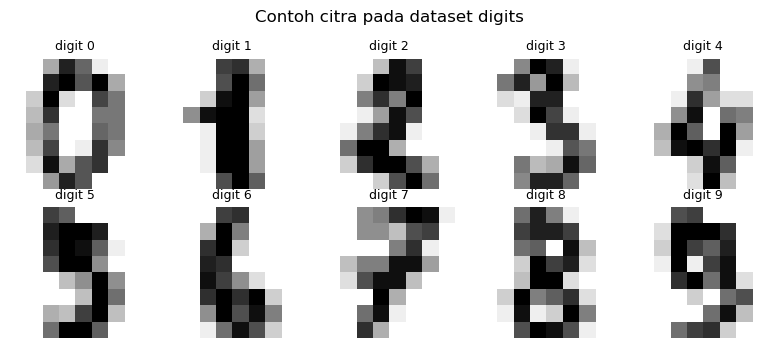

In [3]:
# Contoh satu citra untuk setiap digit
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))
for i, ax in enumerate(axes.ravel()):
    idx = np.where(y == i)[0][0]
    ax.imshow(digits.images[idx], cmap="gray_r")
    ax.set_title(f"digit {i}", fontsize=9)
    ax.axis("off")
fig.suptitle("Contoh citra pada dataset digits")
plt.tight_layout()
plt.show()

## 2. Pra-pemrosesan: Piksel Mentah vs Standardisasi

Sebelum clustering, dibandingkan dua pilihan representasi fitur dengan parameter HDBSCAN default: piksel mentah dan hasil `StandardScaler`. Untuk data citra, standardisasi berisiko **memperbesar bobot piksel tepi** yang nilainya hampir selalu nol (variansnya sangat kecil sehingga nilainya justru membesar saat dibagi standar deviasi).

In [4]:
X_std = StandardScaler().fit_transform(X)

for name, X_used in [("Piksel mentah", X), ("StandardScaler", X_std)]:
    model = hdbscan.HDBSCAN().fit(X_used)
    lab = model.labels_
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    n_no = int((lab == -1).sum())
    print(f"{name:14s} -> cluster: {n_cl:2d} | noise: {n_no:4d} | ARI: {adjusted_rand_score(y, lab):.3f}")

Piksel mentah  -> cluster: 20 | noise:  589 | ARI: 0.416


StandardScaler -> cluster: 16 | noise:  944 | ARI: 0.188


Hasil di atas menunjukkan standardisasi **menurunkan** kualitas clustering (cluster lebih sedikit, noise jauh lebih banyak, ARI lebih rendah), sehingga clustering selanjutnya dilakukan pada **piksel mentah**.

## 3. Eksperimen Hyperparameter untuk Memilih Parameter

Dilakukan pencarian singkat pada `min_cluster_size` dan `min_samples`, dinilai dengan jumlah cluster, jumlah noise, dan **Adjusted Rand Index (ARI)** terhadap label asli (ARI = 1 berarti identik, 0 berarti acak).

In [5]:
rows = []
for mcs, ms in [(15, 2), (30, 2), (50, 2), (30, 3), (30, 5), (30, 10)]:
    model = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms).fit(X)
    lab = model.labels_
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    n_no = int((lab == -1).sum())
    rows.append({
        "min_cluster_size": mcs,
        "min_samples": ms,
        "jumlah cluster": n_cl,
        "jumlah noise": n_no,
        "noise (%)": round(100 * n_no / len(lab), 1),
        "ARI": round(adjusted_rand_score(y, lab), 3),
    })

pd.DataFrame(rows)

,min_cluster_size,min_samples,jumlah cluster,jumlah noise,noise (%),ARI
0,15,2,15,411,22.9,0.578
1,30,2,10,449,25.0,0.590
2,50,2,10,449,25.0,0.590
3,30,3,11,461,25.7,0.546
4,30,5,10,655,36.4,0.399
5,30,10,8,789,43.9,0.283


Parameter final yang dipilih: **`min_cluster_size=30`, `min_samples=2`** — menghasilkan 10 cluster (sama dengan jumlah digit asli) dengan noise sekitar 25% dan ARI tertinggi di antara konfigurasi yang jumlah cluster-nya wajar. Nilai `min_samples` yang lebih besar terbukti menambah noise tanpa memperbaiki pemisahan.

## 4. Clustering Final dengan HDBSCAN

In [6]:
hdb = hdbscan.HDBSCAN(min_cluster_size=30, min_samples=2).fit(X)
labels = hdb.labels_

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())
print(f"Jumlah cluster : {n_clusters}")
print(f"Jumlah noise   : {n_noise} dari {len(labels)} data ({100 * n_noise / len(labels):.1f}%)")

Jumlah cluster : 10
Jumlah noise   : 449 dari 1797 data (25.0%)


## 5. Evaluasi Hasil Clustering

Metrik internal (Silhouette, Davies-Bouldin) dihitung **tanpa noise**, sedangkan ARI/NMI dihitung pada seluruh data (dibandingkan label asli). Tabel silang (crosstab) menunjukkan komposisi tiap cluster terhadap digit aslinya.

In [7]:
mask = labels != -1

print(f"Rata-rata probabilitas keanggotaan (non-noise) : {hdb.probabilities_[mask].mean():.3f}")
print(f"Adjusted Rand Index (semua data)               : {adjusted_rand_score(y, labels):.3f}")
print(f"Adjusted Rand Index (hanya data non-noise)     : {adjusted_rand_score(y[mask], labels[mask]):.3f}")
print(f"Normalized Mutual Info                         : {normalized_mutual_info_score(y, labels):.3f}")
print(f"Silhouette Score (tanpa noise)                 : {silhouette_score(X[mask], labels[mask]):.3f}")
print(f"Davies-Bouldin Index (tanpa noise)             : {davies_bouldin_score(X[mask], labels[mask]):.3f}")

Rata-rata probabilitas keanggotaan (non-noise) : 0.918
Adjusted Rand Index (semua data)               : 0.590
Adjusted Rand Index (hanya data non-noise)     : 0.967
Normalized Mutual Info                         : 0.786
Silhouette Score (tanpa noise)                 : 0.229
Davies-Bouldin Index (tanpa noise)             : 1.566


In [8]:
# Komposisi setiap cluster terhadap digit asli
ct = pd.crosstab(
    pd.Series(labels, name="Cluster HDBSCAN"),
    pd.Series(y, name="Digit asli"),
)
ct

Digit asli,0,1,2,3,4,5,6,7,8,9
Cluster HDBSCAN,,,,,,,,,,
-1,1,51,16,53,17,48,19,20,153,71
0,0,0,0,0,0,0,0,159,0,0
1,177,0,0,0,0,0,0,0,0,0
2,0,0,161,0,0,0,0,0,0,0
3,0,0,0,0,164,0,0,0,0,0
4,0,0,0,130,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,109
6,0,0,0,0,0,134,0,0,0,0
7,0,0,0,0,0,0,162,0,0,0


In [9]:
# Sebaran noise per digit asli
noise_per_digit = pd.Series(y[labels == -1]).value_counts().sort_index()
total_per_digit = pd.Series(y).value_counts().sort_index()
pd.DataFrame({
    "jumlah noise": noise_per_digit,
    "total data": total_per_digit,
    "noise (%)": (100 * noise_per_digit / total_per_digit).round(1),
})

,jumlah noise,total data,noise (%)
0,1,178,0.6
1,51,182,28.0
2,16,177,9.0
3,53,183,29.0
4,17,181,9.4
5,48,182,26.4
6,19,181,10.5
7,20,179,11.2
8,153,174,87.9
9,71,180,39.4


## 6. Visualisasi dengan PCA dan t-SNE

Karena data berdimensi 64, hasil clustering divisualisasikan pada proyeksi 2D **PCA** (linear) dan **t-SNE** (non-linear). Noise digambarkan sebagai tanda silang hitam.

Explained variance ratio: [0.149 0.136]


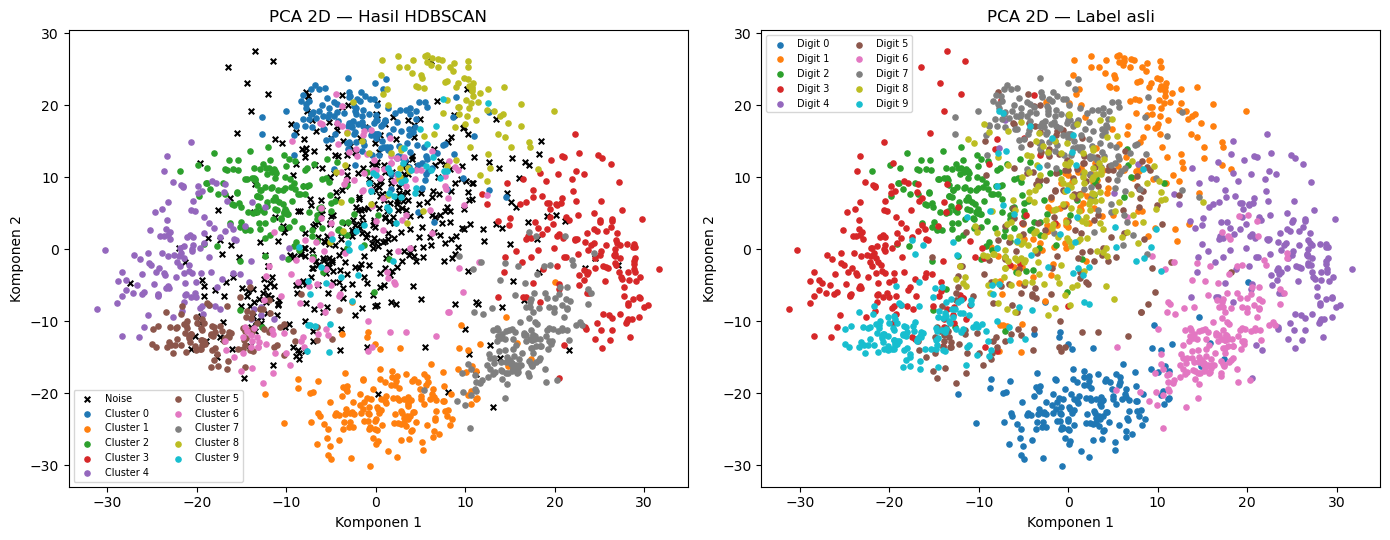

In [10]:
# Proyeksi PCA
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))


def scatter_2d(ax, Z, lab, title, prefix="Cluster"):
    for k in sorted(set(lab)):
        m = lab == k
        if k == -1:
            ax.scatter(Z[m, 0], Z[m, 1], s=16, marker="x", color="black", label="Noise")
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=14, color=plt.cm.tab10(k % 10), label=f"{prefix} {k}")
    ax.set_title(title)
    ax.set_xlabel("Komponen 1")
    ax.set_ylabel("Komponen 2")
    ax.legend(fontsize=7, ncol=2)


fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
scatter_2d(axes[0], X_pca, labels, "PCA 2D — Hasil HDBSCAN")
scatter_2d(axes[1], X_pca, y, "PCA 2D — Label asli", prefix="Digit")
plt.tight_layout()
plt.show()

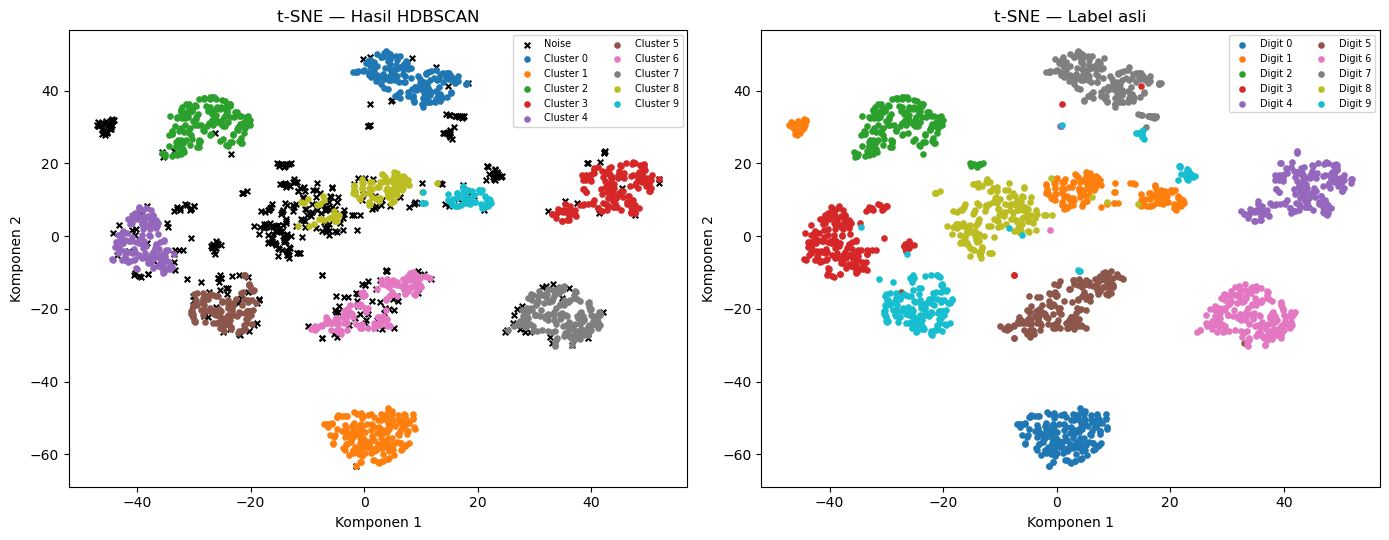

In [11]:
# Proyeksi t-SNE (perlu beberapa saat)
tsne = TSNE(n_components=2, perplexity=30, random_state=0)
X_tsne = tsne.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
scatter_2d(axes[0], X_tsne, labels, "t-SNE — Hasil HDBSCAN")
scatter_2d(axes[1], X_tsne, y, "t-SNE — Label asli", prefix="Digit")
plt.tight_layout()
plt.show()

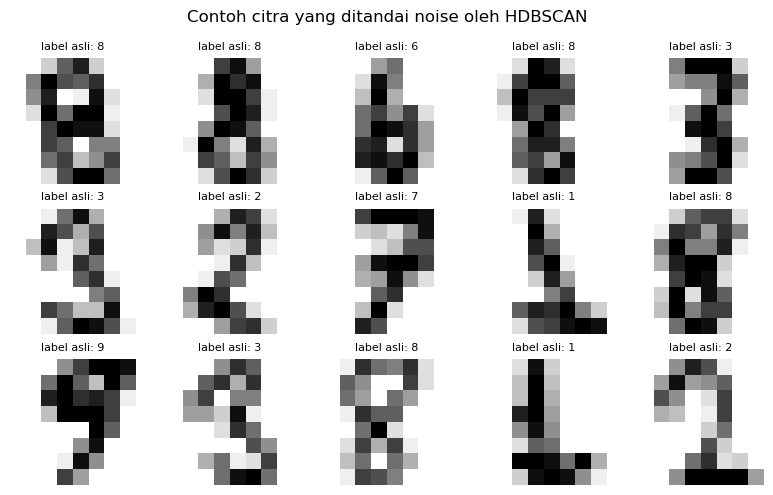

In [12]:
# Contoh citra yang ditandai noise (15 sampel acak)
rng = np.random.RandomState(0)
noise_idx = rng.choice(np.where(labels == -1)[0], size=15, replace=False)

fig, axes = plt.subplots(3, 5, figsize=(8, 5))
for ax, idx in zip(axes.ravel(), noise_idx):
    ax.imshow(digits.images[idx], cmap="gray_r")
    ax.set_title(f"label asli: {y[idx]}", fontsize=8)
    ax.axis("off")
fig.suptitle("Contoh citra yang ditandai noise oleh HDBSCAN")
plt.tight_layout()
plt.show()

## 7. Analisis: Apakah Hasil HDBSCAN Sesuai Label Asli?

**Jumlah cluster.** HDBSCAN membentuk **10 cluster** — kebetulan sama banyak dengan jumlah digit asli. Setiap cluster didominasi oleh **satu digit** yang sama, yang berarti cluster yang terbentuk sangat murni: hampir tidak ada cluster yang "campur" dua digit sama rata.

**Banyaknya noise.** Sebanyak **449 dari 1.797 data (25,0%)** ditandai sebagai noise. Noise menyebar tidak merata: digit **8** paling banyak menjadi noise (153 dari 174 data, hanya 21 yang masuk cluster), disusul digit 9 (71), 3 (53), 1 (51), dan 5 (48); sedangkan digit 0 hampir tidak ada noise (1 data). Artinya distribusi *gaya tulisan* paling beragam pada digit 8, 9, dan 3 sehingga mayoritas sampelnya tidak cukup padat untuk membentuk cluster — perilaku wajar untuk clustering berbasis densitas pada tulisan tangan.

**Kesesuaian dengan label asli.**
* Pada data yang **bukan noise**, kesesuaiannya sangat tinggi: **ARI = 0.967** dan setiap cluster didominasi satu digit (lihat crosstab).
* Secara keseluruhan (termasuk noise), **ARI = 0.590** dan NMI = 0.786 — turun karena seperempat data memang sengaja dibiarkan tidak terkelompokkan, bukan karena salah kelompok.
* Rata-rata probabilitas keanggotaan titik non-noise adalah **0.918**, menunjukkan anggota cluster umumnya diyakini kuat.

**Ketidaksempurnaan yang menarik untuk dianalisis.**
* Digit **1** terpecah menjadi dua cluster (cluster 9 berisi 52 gambar angka 1 dan cluster 8 berisi 79 gambar angka 1). Ini bukan kesalahan: HDBSCAN menangkap dua "gaya" penulisan angka 1 (misalnya tegak dan miring), jadi jumlah cluster tidak harus sama dengan jumlah kelas.
* Tersisa satu percampuran: cluster 8 memuat 21 gambar angka 8 bersama 79 gambar angka 1 — kedua digit tersebut memang paling sulit dibedakan pada citra 8×8 piksel.
* Silhouette Score tanpa noise hanya 0.229 (Davies-Bouldin 1.566): pada ruang 64 dimensi, cluster digit saling berdekatan sehingga sulit terpisah jauh — tetapi hasil visualisasi (khususnya t-SNE) tetap menunjukkan pemisahan yang jelas antar cluster.

**Jawaban singkat:** ya, hasil HDBSCAN **sangat sesuai dengan label asli** — setiap cluster yang terbentuk berpadanan dengan satu digit, dengan ARI 0.967 pada data non-noise. Perbedaannya hanya pada detail: digit 1 terpecah menjadi dua cluster (dua gaya penulisan), sebagian kecil gambar 8 bercampur dengan 1, dan 25% data ambigu ditandai noise. Ini menunjukkan HDBSCAN menemukan struktur kepadatan data, yang tidak selalu identik dengan label semantik, tetapi sangat mendekati di dataset digits.

## Kesimpulan

* HDBSCAN berhasil mengelompokkan dataset digits **tanpa menentukan jumlah cluster di awal**: terbentuk 10 cluster murni (setiap cluster ≈ satu digit).
* Clustering dilakukan pada **piksel mentah** karena standardisasi fitur justru memperburuk hasil (ARI 0.416 → 0.188 pada parameter default).
* Parameter final `min_cluster_size=30`, `min_samples=2` dipilih dari eksperimen kecil; parameter `min_samples` yang terlalu besar menambah noise tanpa memperbaiki kualitas.
* Sekitar **25% data ditandai noise** — mayoritas dari digit 8, 9, 3, 1, dan 5 yang gaya tulisannya beragam, sehingga tidak semuanya membentuk area padat.
* Secara keseluruhan hasil clustering **sangat sesuai dengan label asli** (ARI 0.967 pada data non-noise; ARI 0.590 dan NMI 0.786 pada seluruh data), dengan satu digit (angka 1) terbagi dua cluster karena perbedaan gaya penulisan.